## Data Preprocessing

In [6]:
# import for libraries and data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


initial_df = pd.read_csv('RawMaterialsPrices.csv')
raw_materials_df = initial_df.rename(columns={
    'REF_DATE': 'date', 'North American Product Classification System (NAPCS)': 'product',
    'VALUE': 'rmpi_index', # rmpi = raw materials price index
    'UOM': "base_period" # every row is 'Index, 202001=100', so January 2020 = 100
})


# parses string to datetime/number
raw_materials_df['date'] = pd.to_datetime(raw_materials_df['date'], format='%Y-%m')
raw_materials_df['rmpi_index'] = pd.to_numeric(raw_materials_df['rmpi_index'], errors='coerce')


# cleans product category to not include NAPCS codes. ex. wheat [112] -> wheat
raw_materials_df['product_category'] = raw_materials_df['product'].str.replace(r'\s*\[.*\]', '', regex=True)


# drops unused columns like GEO and TERMINATED (always empty) and missing index values, then sorts by product type and date
# STATUS 'E' means the value is an estimate from Statistics Canada
main_cols = ['date', 'product_category', 'rmpi_index', 'STATUS']
raw_materials_df = raw_materials_df[main_cols].dropna(subset=['rmpi_index']).sort_values(['product_category', 'date'])


raw_materials_df.head()

,date,product_category,rmpi_index,STATUS
2509,2010-09-01,Animals and animal products,83.9,NaN
2510,2010-10-01,Animals and animal products,81.5,NaN
2511,2010-11-01,Animals and animal products,79.1,NaN
2512,2010-12-01,Animals and animal products,81.0,NaN
2513,2011-01-01,Animals and animal products,82.9,NaN


### Pearson Correlation: Which products' prices move together?


For this method, we used Pearson correlation to see which products have prices that move together. Pearson correlation measures how strongly two variables are linearly related, and gives a value (r) between -1 and 1. An r close to 1 means that when one product's price goes up, the other one usually goes up too. An r close to -1 means they move in opposite directions, and an r close to 0 means there isn't really a relationship.


We calculated the correlation for every pair of products and displayed them in a heatmap. This will show us which products are connected to each other, and whether crops and animal products behave similarly or differently.



Strongest correlations:
product_category  product_category
Wheat             Canola              0.56
                  Barley              0.56
Canola            Soybeans            0.45
Oats              Other oilseeds      0.45
Barley            Other oilseeds      0.45
Canola            Barley              0.41
Wheat             Oats                0.40
                  Corn                0.37
Barley            Oats                0.37
Canola            Oats                0.36


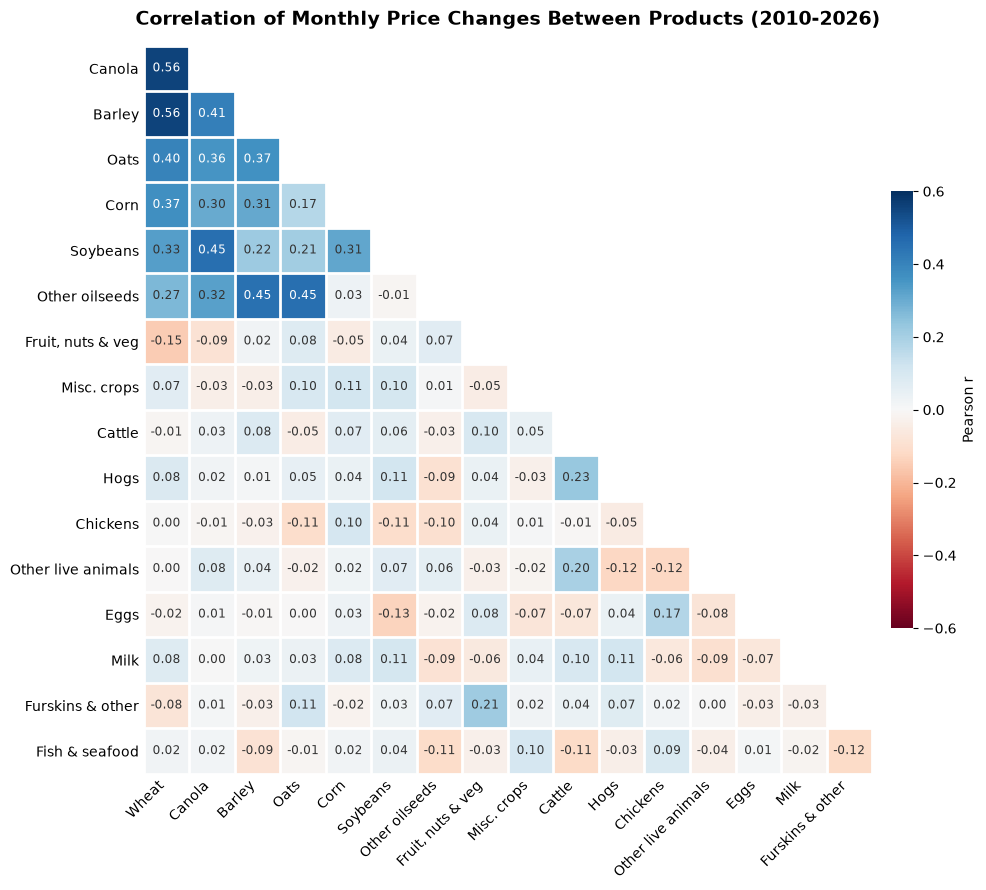

In [7]:
# pivots so each product is its own column and each row is a month
prices_wide = raw_materials_df.pivot(index='date', columns='product_category', values='rmpi_index')


# only keeps the most specific products, since categories like "Crop products" are totals of the others
# maps each full name to a short name for the plot (first 9 are crops, last 8 are animals)
leaf_products = {
    'Wheat': 'Wheat', 'Canola (including rapeseed)': 'Canola', 'Barley': 'Barley', 'Oats': 'Oats',
    'Corn for grain': 'Corn', 'Soybeans': 'Soybeans', 'Oilseeds (except canola and soybeans)': 'Other oilseeds',
    'Fresh fruit, nuts and vegetables, and pulse crops': 'Fruit, nuts & veg', 'Other miscellaneous crop products': 'Misc. crops',
    'Cattle and calves': 'Cattle', 'Hogs': 'Hogs', 'Chickens': 'Chickens', 'Other live animals': 'Other live animals',
    'Eggs in shell': 'Eggs', 'Unprocessed milk': 'Milk', 'Raw furskins, and animal products n.e.c.': 'Furskins & other',
    'Fish, crustaceans, shellfish and other fishery products': 'Fish & seafood',
}


# monthly percent change instead of the raw index, since all prices trend up over time
monthly_change = prices_wide[list(leaf_products)].pct_change() * 100
monthly_change = monthly_change.rename(columns=leaf_products).dropna()


# pearson correlation between every pair of products
corr_matrix = monthly_change.corr(method='pearson')


# prints the strongest pairs (upper triangle only so each pair shows up once)
pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
print('Strongest correlations:')
print(pairs.sort_values(ascending=False).head(10).round(2).to_string())


# only plots the lower triangle since the upper half is a mirror of it (and the diagonal is always 1)
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool))
plot_matrix = corr_matrix.mask(mask).iloc[1:, :-1]


# red = negative, blue = positive, white = no correlation. empty cells are left white
cmap = plt.get_cmap('RdBu').copy()
cmap.set_bad('white')


fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(plot_matrix, cmap=cmap, vmin=-0.6, vmax=0.6)


# writes the correlation in every cell, white text on dark cells so it stays readable
for i in range(plot_matrix.shape[0]):
    for j in range(plot_matrix.shape[1]):
        r = plot_matrix.iloc[i, j]
        if not np.isnan(r):
            label = f'{r:.2f}'.replace('-0.00', '0.00')
            ax.text(j, i, label, ha='center', va='center', fontsize=8.5,
                    color='white' if abs(r) > 0.35 else '#333333')


# product names on both axes
ax.set_xticks(range(plot_matrix.shape[1]))
ax.set_yticks(range(plot_matrix.shape[0]))
ax.set_xticklabels(plot_matrix.columns, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(plot_matrix.index, fontsize=10)


# thin white lines between cells and no border around the plot
ax.set_xticks(np.arange(-0.5, plot_matrix.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, plot_matrix.shape[0]), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='both', length=0)
for spine in ax.spines.values():
    spine.set_visible(False)


ax.set_title('Correlation of Monthly Price Changes Between Products (2010-2026)', fontsize=14, fontweight='bold', pad=15)
cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('Pearson r')
cbar.outline.set_visible(False)
plt.tight_layout()
plt.show()



**Conclusion:** From the heatmap, we can see that grains and oilseeds tend to move together, while animal products mostly don't correlate with anything.


The strongest correlations we found were wheat with canola and wheat with barley (both r = 0.56). The other grains and oilseeds like oats, corn, and soybeans are also moderately correlated with each other, which is why the top left corner of the heatmap is the darkest blue. We think this is because these crops are all sold on world markets, so things like weather, fuel prices, and global demand affect them in similar ways.


On the other hand, the animal products are almost all close to 0, both with crops and with each other. The highest one was cattle and hogs at r = 0.23, which is still pretty weak. This tells us that animal prices are mostly driven by their own separate factors. For later parts of the project, this means we could probably use the grains to help predict each other, but the animal products would need to be looked at individually.



### Mann-Whitney U Test: Have monthly price changes changed since 2020?


We wanted to see if monthly price changes have been different since 2020 (start of COVID) compared to 2010 to 2019. We split the monthly percent changes into two groups, the months from 2010-2019 and the months from 2020-2026. We did this separately for the two overall categories, crops and animals.


We used a Mann-Whitney U test, which compares two independent groups. Instead of using the actual values, it ranks every month from the smallest price change to the largest, and checks whether one group's ranks tend to be higher than the other's. We chose it over a two-sample t-test because ranks aren't affected much by outliers, and the monthly changes have some big ones. As a check, we also ran a Welch's t-test to see if it agrees.


- **H0:** monthly price changes since 2020 come from the same distribution as monthly price changes from 2010-2019.
- **HA:** monthly price changes since 2020 come from a different distribution (two-tailed).
- **Significance level:** α = 0.05. Since we run the test twice (crops and animals), we use a Bonferroni correction: α = 0.05 / 2 = 0.025.

Months in each group: 111 (2010-2019), 81 (2020-2026)
Bonferroni-corrected alpha: 0.025

                 median 2010-2019 (%)  median 2020-2026 (%)  U statistic  p-value  Welch p-value  reject H0?
category                                                                                                    
Crop products                   0.000                 0.691       4058.0    0.250          0.398       False
Animal products                 0.224                 0.807       4070.5    0.264          0.232       False

Average price index by year (Jan 2020 = 100):
date              2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
product_category                                                                                                      
Crop products       90   100   100   100    95    98    96    96    97    98   103   145   168   148   133   134   135
Animal products     81    90    92    95   107   106    98   102   100 

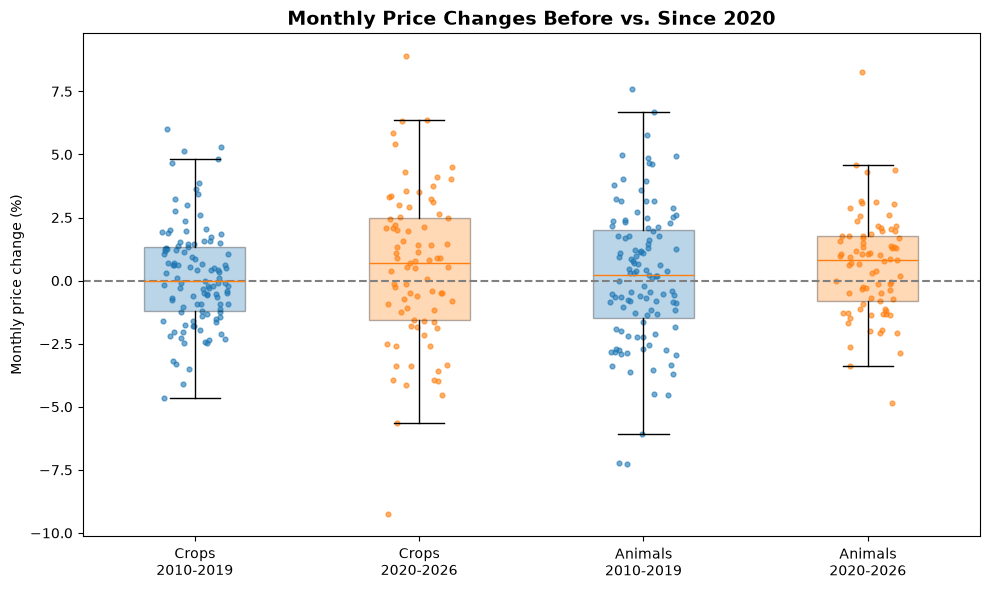

In [3]:
# monthly percent change for the two overall categories
categories = {'Crop products': 'Crop products', 'Animals and animal products': 'Animal products'}
category_change = prices_wide[list(categories)].pct_change() * 100
category_change = category_change.rename(columns=categories).dropna()


# splits the months into two independent groups: 2010-2019 and 2020 onward
before = category_change[category_change.index.year < 2020]
since = category_change[category_change.index.year >= 2020]
print(f'Months in each group: {len(before)} (2010-2019), {len(since)} (2020-2026)')


# bonferroni correction since we're running the test twice
alpha = 0.05 / len(categories)
print(f'Bonferroni-corrected alpha: {alpha}\n')


# mann-whitney u test for each category, plus a welch's t-test as a check
results = []
for category in category_change.columns:
    mw = stats.mannwhitneyu(before[category], since[category], alternative='two-sided')
    welch = stats.ttest_ind(before[category], since[category], equal_var=False)
    results.append({'category': category, 'median 2010-2019 (%)': before[category].median(), 'median 2020-2026 (%)': since[category].median(),
                    'U statistic': mw.statistic, 'p-value': mw.pvalue, 'Welch p-value': welch.pvalue, 'reject H0?': mw.pvalue < alpha})
results = pd.DataFrame(results).set_index('category')
print(results.round(3).to_string())


# average price index each year (Jan 2020 = 100). the test compares monthly changes, so this shows how the price level itself moved
levels = prices_wide[list(categories)].rename(columns=categories)
print('\nAverage price index by year (Jan 2020 = 100):')
print(levels.groupby(levels.index.year).mean().round(0).astype(int).T.to_string())


# box plot for each group with every month drawn as a dot
groups = [before['Crop products'], since['Crop products'], before['Animal products'], since['Animal products']]
colors = ['tab:blue', 'tab:orange'] * 2


fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(groups, patch_artist=True, showfliers=False)
for i, (box, months, color) in enumerate(zip(bp['boxes'], groups, colors), start=1):
    box.set(facecolor=color, alpha=0.3)
    ax.scatter(i + np.random.uniform(-0.15, 0.15, len(months)), months, s=12, color=color, alpha=0.6)


# dashed line at 0 so it's easy to see price increases vs decreases
ax.axhline(0, color='gray', linestyle='--')
ax.set_xticklabels(['Crops\n2010-2019', 'Crops\n2020-2026', 'Animals\n2010-2019', 'Animals\n2020-2026'])
ax.set_ylabel('Monthly price change (%)')
ax.set_title('Monthly Price Changes Before vs. Since 2020', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Conclusion:** We fail to reject the null hypothesis for both crops (p = 0.25) and animals (p = 0.26), since both p-values are above α = 0.025. The Welch's t-test agrees (p = 0.40 for crops and p = 0.23 for animals). So we don't have enough evidence to say monthly price changes have been different since 2020.


The median monthly change did go up a little, from 0.00% to 0.69% for crops and from 0.22% to 0.81% for animals. But prices move around so much from month to month that a difference this small could easily happen by chance. In the plot, the boxes for each pair overlap almost completely.


This doesn't mean prices didn't go up. Prices are clearly higher now, but the test looks at the typical month, not the overall price level. The yearly average crop index stayed between 95 and 100 from 2011 to 2019, jumped to 145 in 2021 and 168 in 2022, and then leveled off around 133-135 from 2024 on, so most of the increase came in a short burst and the typical month didn't change much. Animal prices rose more steadily, from 98 in 2020 to 160 in 2026 (through Sep), but through many small monthly increases that are small compared to how much prices move from month to month.


One limitation is that the Mann-Whitney test assumes each month is independent, but one month's price change can be related to the next month's, so the p-values are only approximate.